# Filtering NO2 Tempo parquet files including cloud data + all hours in output

* This now includes effective cloud fraction data in the dataset 


Due to memory issues when trying to combine all months for no2 pulse detection, this notebook works to cut down on memory usage by filtering files before using the files in a separate notebook for pulse detection. Filtering is done by removing pixels with too high of effective cloud fraction or snow/ice cover, as well as removing columns that are unneccesary for data analysis. It saves the filtered dataframes as new files. 

* 5/04/26 -- lowering cloud fraction to be 0.1 instead of 0.15 

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
from datetime import datetime, timezone
from tqdm import tqdm

In [3]:
mar_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/full_month_combined_all_hours/all_tempo_hours_files/all_tempo_hours_no2_L3_VO3_2024_03_combined.parquet'
apr_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/full_month_combined_all_hours/all_tempo_hours_files/all_tempo_hours_no2_L3_VO3_2024_04_combined.parquet'
may_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/full_month_combined_all_hours/all_tempo_hours_files/all_tempo_hours_no2_L3_VO3_2024_05_combined.parquet'
june_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/full_month_combined_all_hours/all_tempo_hours_files/all_tempo_hours_no2_L3_VO3_2024_06_combined.parquet'
july_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/full_month_combined_all_hours/all_tempo_hours_files/all_tempo_hours_no2_L3_VO3_2024_07_combined.parquet'

In [4]:
#function for filtering 
def filter_no2_dataframe(df, drop_extra_cols=False):
    #combine date and time into datetime
    df['datetime'] =pd.to_datetime(df['date'].astype(str) + ' ' + df['time'].astype(str),format='%Y-%m-%d %H:%M:%S.%f',errors='coerce')

    # floored hour column
    df['hour'] = df['datetime'].dt.floor('h').dt.time

    # quality filtering
    df_filt =df[
        (df['eff_cloud_fraction'] <= 0.10) &
        (df['snow_ice_fraction'] < 0.01) & 
        (df['solar_zenith_angle'] <70) & 
        (df['no2'] > 0)].copy()

    #optionally drop extra columns--can change! (I used to drop them, now I don't because I use them in data analysis) 
    if drop_extra_cols:
        cols_to_drop = ['amf_cloud_fraction','snow_ice_fraction',
                        'eff_cloud_fraction','no2_uncertainty']
        df_filt = df_filt.drop(columns=cols_to_drop, errors='ignore')

    return df_filt

## first filter for march

In [4]:
mar_df=pd.read_parquet(mar_file, engine = 'pyarrow')

In [5]:
mar_df_filt = filter_no2_dataframe(mar_df, drop_extra_cols=False)

In [6]:
#output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/filtered_mar_no2.parquet' #this is old ouput from CF < 0.15
output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_mar_no2.parquet' #new path for CF <= 0.1

mar_df_filt.to_parquet(output_file, engine='pyarrow')

## first filtering for april

In [4]:
apr_df = pd.read_parquet(apr_file, engine = 'pyarrow')

In [5]:
apr_df_filt = filter_no2_dataframe(apr_df, drop_extra_cols=False)

IOStream.flush timed out


In [6]:
#output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/filtered_apr_no2.parquet' #this is old ouput from CF < 0.15
output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_apr_no2.parquet' #new path for CF <= 0.1
apr_df_filt.to_parquet(output_file, engine='pyarrow')

## now filtering for may

In [7]:
may_df = pd.read_parquet(may_file, engine='pyarrow')

In [8]:
may_df_filt = filter_no2_dataframe(may_df, drop_extra_cols=False)

In [9]:
#output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/filtered_may_no2.parquet' #this is old ouput from CF < 0.15
output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_may_no2.parquet' #new path for CF <= 0.1
may_df_filt.to_parquet(output_file, engine='pyarrow')

## now filtering for june

In [4]:
june_df = pd.read_parquet(june_file, engine = 'pyarrow')

In [5]:
june_df_filt = filter_no2_dataframe(june_df, drop_extra_cols=False)

In [6]:
#output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/filtered_june_no2.parquet' #this is old ouput from CF < 0.15
output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_june_no2.parquet' #new path for CF <= 0.1

june_df_filt.to_parquet(output_file, engine='pyarrow')

## filter for july 

In [7]:
july_df = pd.read_parquet(july_file, engine = 'pyarrow')

In [8]:
july_df_filt = filter_no2_dataframe(july_df, drop_extra_cols = False) 

In [9]:
#output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/filtered_july_no2.parquet' #this is old ouput from CF < 0.15
output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_july_no2.parquet' #new path for CF <= 0.1

july_df_filt.to_parquet(output_file, engine='pyarrow')

## restarted kernel, now going to concatenate all no2 data to one df 

In [2]:
mar_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_mar_no2.parquet'
apr_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_apr_no2.parquet'
may_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_may_no2.parquet'
june_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_june_no2.parquet'
july_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_july_no2.parquet'

In [3]:
mar_df = pd.read_parquet(mar_file,engine='pyarrow')
apr_df = pd.read_parquet(apr_file,engine= 'pyarrow')
may_df = pd.read_parquet(may_file,engine= 'pyarrow')
june_df = pd.read_parquet(june_file,engine= 'pyarrow')
july_df = pd.read_parquet(july_file,engine='pyarrow')

In [4]:
all_no2 = pd.concat([mar_df, apr_df, may_df, june_df, july_df], ignore_index=True)

In [5]:
output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/lowCF_filtered_mar-july_no2.parquet'
#output_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/months_filtered_all_hours/filtered_mar-july_no2.parquet' #old file path 

all_no2.to_parquet(output_file, engine='pyarrow')

In [6]:
all_no2

,time,latitude,longitude,no2,no2_uncertainty,eff_cloud_fraction,amf_cloud_fraction,snow_ice_fraction,solar_zenith_angle,date,datetime,hour
0,13:41:26.146071,38.529999,-80.129997,2.471444e+15,1.348177e+15,0.090753,0.302874,0.0,67.274025,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
1,13:41:26.146071,38.529999,-80.110001,2.473664e+15,1.348200e+15,0.090776,0.302943,0.0,67.273994,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
2,13:41:26.146071,38.529999,-80.089996,1.992558e+15,1.381077e+15,0.092831,0.307594,0.0,67.256371,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
3,13:41:26.146071,38.529999,-80.070000,1.686709e+15,1.404502e+15,0.094362,0.311206,0.0,67.244247,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
4,13:41:26.146071,38.529999,-80.050003,1.705266e+15,1.401993e+15,0.094726,0.312149,0.0,67.243988,2024-03-01,2024-03-01 13:41:26.146071,13:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
310706853,23:33:15.152400,48.650002,-100.769997,6.279737e+14,7.524522e+14,0.096853,0.266829,0.0,66.865189,2024-07-31,2024-07-31 23:33:15.152400,23:00:00
310706854,23:33:15.152400,48.650002,-100.750000,6.621763e+14,7.463677e+14,0.095777,0.263508,0.0,66.865089,2024-07-31,2024-07-31 23:33:15.152400,23:00:00
310706855,23:33:15.152400,48.650002,-100.730003,6.829422e+14,7.549389e+14,0.096098,0.264633,0.0,66.866211,2024-07-31,2024-07-31 23:33:15.152400,23:00:00
310706856,23:33:15.152400,48.689999,-103.989998,4.286914e+13,1.063565e+15,0.098478,0.309741,0.0,65.116661,2024-07-31,2024-07-31 23:33:15.152400,23:00:00


In [7]:
all_no2['amf_cloud_fraction'].describe()

count    3.107069e+08
mean     2.715919e-01
std      6.826629e-02
min      0.000000e+00
25%      2.300775e-01
50%      2.773939e-01
75%      3.200732e-01
max      4.899188e-01
Name: amf_cloud_fraction, dtype: float64

In [8]:
all_no2['eff_cloud_fraction'].describe()

count    3.107069e+08
mean     6.903040e-02
std      1.949147e-02
min      0.000000e+00
25%      5.530771e-02
50%      7.101803e-02
75%      8.492165e-02
max      1.000000e-01
Name: eff_cloud_fraction, dtype: float64

In [9]:
all_no2['snow_ice_fraction'].describe()

count    3.107069e+08
mean     1.277074e-06
std      8.844104e-05
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      9.999962e-03
Name: snow_ice_fraction, dtype: float64

Text(0.5, 1.0, 'Effective cloud fraction boxplot when filter for Eff CF <0.1')

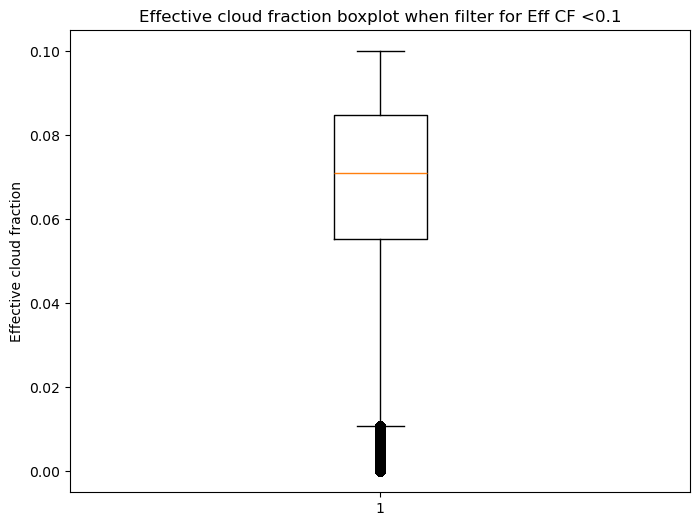

In [12]:
plt.figure(figsize=(8,6))
plt.boxplot(all_no2['eff_cloud_fraction'])
plt.ylabel('Effective cloud fraction')
plt.title('Effective cloud fraction boxplot when filter for Eff CF <0.1') 

Text(0, 0.5, 'AMF cloud fraction boxplot when filter for Eff CF <0.1')

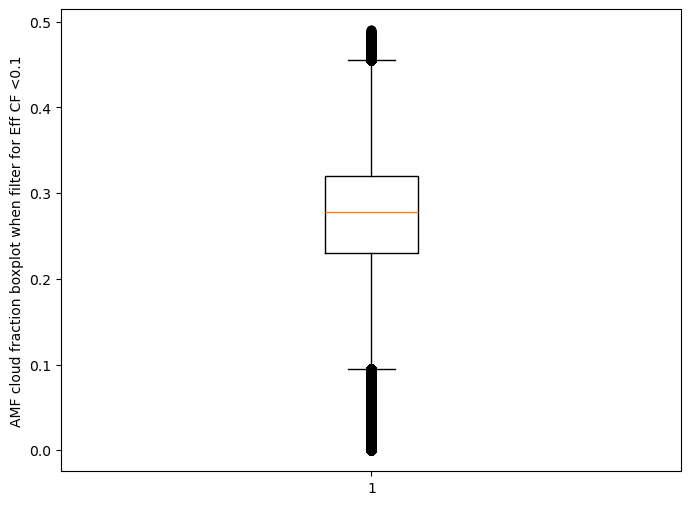

In [13]:
plt.figure(figsize=(8,6))
plt.boxplot(all_no2['amf_cloud_fraction'])
plt.ylabel('AMF cloud fraction boxplot when filter for Eff CF <0.1')